Original Sensor Dataset:
   Temperature  Vibration   Pressure    Current   Humidity
0    27.889498  11.771789  53.029532  17.422968  59.515084
1    25.509841   9.172286  57.493148  19.787018  60.910767
2    27.002696  10.477178  43.613310  11.871556  58.835515
3    28.922153  13.042685  51.943915  15.513702  63.973687
4    24.995763   9.361509  45.503815  12.613564  59.671757

Dataset Shape: (500, 5)

Missing Values After Imputation:
Temperature    0
Vibration      0
Pressure       0
Current        0
Humidity       0
dtype: int64

Probabilistic PCA Results
Explained Variance: [2.4088599  1.93926237]
Explained Variance Ratio: [0.48080844 0.38707677]

Estimated Noise Variance:
0.22063258957808976

Reconstructed Sensor Data:
   Temperature  Vibration   Pressure    Current   Humidity
0    26.671654  11.103059  52.301305  16.285959  61.234396
1    24.311358   9.285581  57.465370  19.055682  61.758851
2    26.331318  11.034507  43.951399  11.760323  58.769470
3    30.002320  13.508217  52.51

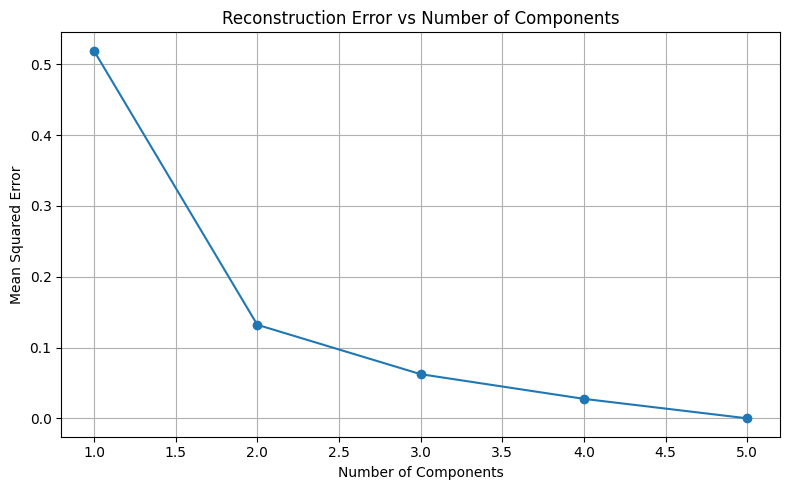

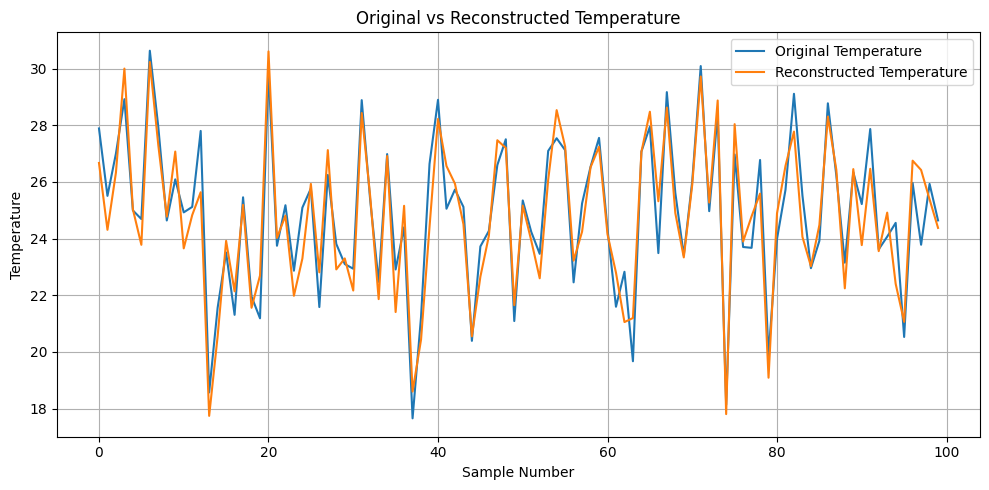

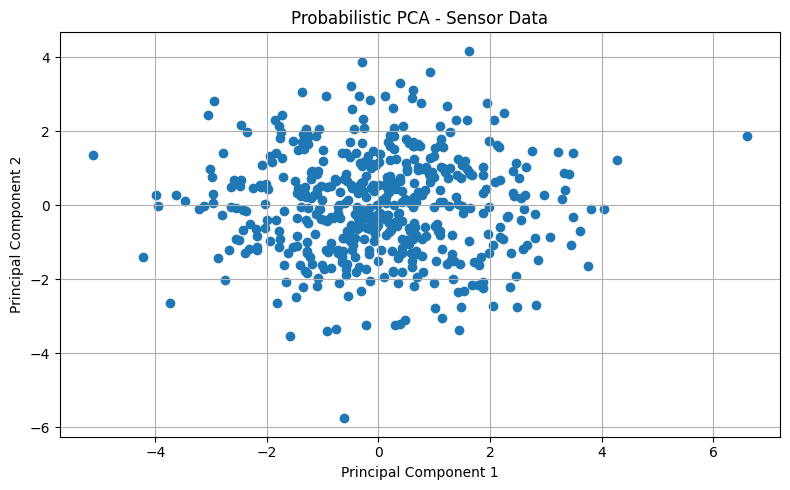


New Generated Sensor Samples:
   Temperature  Vibration  Pressure  Current  Humidity
0        26.26       9.07     48.65    16.72     59.18
1        24.33       8.74     46.96    13.98     60.00
2        26.64       8.95     47.69    18.47     59.31
3        22.93       8.59     50.49    15.11     59.70
4        24.28       9.50     44.30    13.29     58.68
5        29.68      11.13     45.49    10.39     60.00
6        25.37      10.71     46.26    13.35     58.26
7        28.66      16.05     45.54    10.59     58.59
8        26.21      12.52     50.72    13.06     60.70
9        23.48       6.29     51.91    14.96     58.41


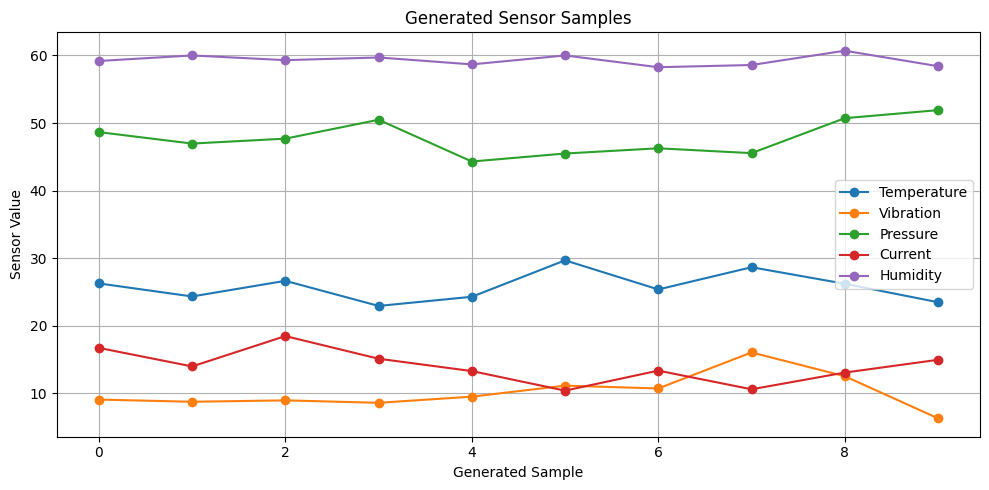


Final Reconstruction Comparison:
   Number of Components  Reconstruction MSE
0                     1              0.5192
1                     2              0.1321
2                     3              0.0624
3                     4              0.0275
4                     5              0.0000


In [25]:

# EXPERIMENT 20: PROBABILISTIC PCA AND RECONSTRUCTION ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# --------------------------------------------------
# 1. GENERATE SYNTHETIC SENSOR DATA
# --------------------------------------------------

np.random.seed(42)

n_samples = 500

# Generate two hidden factors
factor1 = np.random.normal(0, 1, n_samples)
factor2 = np.random.normal(0, 1, n_samples)

# Generate sensor readings
data = {
    'Temperature': 25 + 3*factor1 + np.random.normal(0, 1, n_samples),
    'Vibration': 10 + 2*factor1 + np.random.normal(0, 1, n_samples),
    'Pressure': 50 + 4*factor2 + np.random.normal(0, 1, n_samples),
    'Current': 15 + 2*factor2 + np.random.normal(0, 1, n_samples),
    'Humidity': 60 + factor1 + factor2 + np.random.normal(0, 1, n_samples)
}

df = pd.DataFrame(data)

# Introduce missing values
for col in df.columns:
    missing_indices = np.random.choice(n_samples, 10, replace=False)
    df.loc[missing_indices, col] = np.nan

print("Original Sensor Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

# --------------------------------------------------
# 2. HANDLE MISSING VALUES
# --------------------------------------------------

imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(df)

df_clean = pd.DataFrame(X_imputed, columns=df.columns)

print("\nMissing Values After Imputation:")
print(df_clean.isnull().sum())

# --------------------------------------------------
# 3. STANDARDIZE SENSOR DATA
# --------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# --------------------------------------------------
# 4. FIT PROBABILISTIC PCA (2 COMPONENTS)
# --------------------------------------------------

ppca = PCA(n_components=2)
X_pca = ppca.fit_transform(X_scaled)

print("\nProbabilistic PCA Results")
print("Explained Variance:", ppca.explained_variance_)
print("Explained Variance Ratio:", ppca.explained_variance_ratio_)

# Estimate noise variance
noise_variance = ppca.noise_variance_

print("\nEstimated Noise Variance:")
print(noise_variance)

# --------------------------------------------------
# 5. RECONSTRUCT DATA USING 2 COMPONENTS
# --------------------------------------------------

X_reconstructed_scaled = ppca.inverse_transform(X_pca)

X_reconstructed = scaler.inverse_transform(
    X_reconstructed_scaled
)

reconstructed_df = pd.DataFrame(
    X_reconstructed,
    columns=df.columns
)

print("\nReconstructed Sensor Data:")
print(reconstructed_df.head())

# --------------------------------------------------
# 6. COMPUTE RECONSTRUCTION ERROR
# --------------------------------------------------

mse = np.mean((X_scaled - X_reconstructed_scaled)**2)

print("\nReconstruction Mean Squared Error (2 Components):")
print(round(mse, 4))

# --------------------------------------------------
# 7. COMPARE RECONSTRUCTION ERROR WITH COMPONENTS
# --------------------------------------------------

errors = []

for n_components in range(1, 6):

    pca_model = PCA(n_components=n_components)

    transformed = pca_model.fit_transform(X_scaled)

    reconstructed = pca_model.inverse_transform(transformed)

    error = np.mean((X_scaled - reconstructed)**2)

    errors.append(error)

    print(
        f"Components: {n_components}, "
        f"Reconstruction Error: {error:.4f}"
    )

# Plot reconstruction error
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 6),
    errors,
    marker='o'
)

plt.title("Reconstruction Error vs Number of Components")
plt.xlabel("Number of Components")
plt.ylabel("Mean Squared Error")

plt.grid(True)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. VISUALIZE ORIGINAL AND RECONSTRUCTED DATA
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    df_clean['Temperature'].values[:100],
    label='Original Temperature'
)

plt.plot(
    reconstructed_df['Temperature'].values[:100],
    label='Reconstructed Temperature'
)

plt.title("Original vs Reconstructed Temperature")
plt.xlabel("Sample Number")
plt.ylabel("Temperature")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 9. VISUALIZE PCA COMPONENTS
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1]
)

plt.title("Probabilistic PCA - Sensor Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.grid(True)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 10. GENERATE NEW SYNTHETIC SENSOR SAMPLES
# --------------------------------------------------

# Generate latent scores using learned component variance
latent_scores = np.random.normal(
    0,
    np.sqrt(ppca.explained_variance_),
    size=(10, 2)
)

# Generate Gaussian noise using estimated PPCA noise variance
noise = np.random.normal(
    0,
    np.sqrt(ppca.noise_variance_),
    size=(10, 5)
)

# Generate new samples in standardized space
new_samples_scaled = (
    ppca.mean_
    + latent_scores @ ppca.components_
    + noise
)

# Convert to original sensor units
new_samples = scaler.inverse_transform(
    new_samples_scaled
)

new_samples_df = pd.DataFrame(
    new_samples,
    columns=df.columns
)

print("\nNew Generated Sensor Samples:")
print(new_samples_df.round(2))

# --------------------------------------------------
# 11. VISUALIZE GENERATED SENSOR SAMPLES
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    new_samples_df['Temperature'],
    marker='o',
    label='Temperature'
)

plt.plot(
    new_samples_df['Vibration'],
    marker='o',
    label='Vibration'
)

plt.plot(
    new_samples_df['Pressure'],
    marker='o',
    label='Pressure'
)

plt.plot(
    new_samples_df['Current'],
    marker='o',
    label='Current'
)

plt.plot(
    new_samples_df['Humidity'],
    marker='o',
    label='Humidity'
)

plt.title("Generated Sensor Samples")
plt.xlabel("Generated Sample")
plt.ylabel("Sensor Value")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 12. FINAL COMPARISON
# --------------------------------------------------

comparison = pd.DataFrame({
    'Number of Components': range(1, 6),
    'Reconstruction MSE': errors
})

print("\nFinal Reconstruction Comparison:")
print(comparison.round(4))
